# Problem Statement

## **Business Context**

"Visit with Us," a leading travel company, is revolutionizing the tourism industry by leveraging data-driven strategies to optimize operations and customer engagement. While introducing a new package offering, such as the Wellness Tourism Package, the company faces challenges in targeting the right customers efficiently. The manual approach to identifying potential customers is inconsistent, time-consuming, and prone to errors, leading to missed opportunities and suboptimal campaign performance.

To address these issues, the company aims to implement a scalable and automated system that integrates customer data, predicts potential buyers, and enhances decision-making for marketing strategies. By utilizing an MLOps pipeline, the company seeks to achieve seamless integration of data preprocessing, model development, deployment, and CI/CD practices for continuous improvement. This system will ensure efficient targeting of customers, timely updates to the predictive model, and adaptation to evolving customer behaviors, ultimately driving growth and customer satisfaction.


## **Objective**

As an MLOps Engineer at "Visit with Us," your responsibility is to design and deploy an MLOps pipeline on GitHub to automate the end-to-end workflow for predicting customer purchases. The primary objective is to build a model that predicts whether a customer will purchase the newly introduced Wellness Tourism Package before contacting them. The pipeline will include data cleaning, preprocessing, transformation, model building, training, evaluation, and deployment, ensuring consistent performance and scalability. By leveraging GitHub Actions for CI/CD integration, the system will enable automated updates, streamline model deployment, and improve operational efficiency. This robust predictive solution will empower policymakers to make data-driven decisions, enhance marketing strategies, and effectively target potential customers, thereby driving customer acquisition and business growth.

## **Data Description**

The dataset contains customer and interaction data that serve as key attributes for predicting the likelihood of purchasing the Wellness Tourism Package. The detailed attributes are:

**Customer Details**
- **CustomerID:** Unique identifier for each customer.
- **ProdTaken:** Target variable indicating whether the customer has purchased a package (0: No, 1: Yes).
- **Age:** Age of the customer.
- **TypeofContact:** The method by which the customer was contacted (Company Invited or Self Inquiry).
- **CityTier:** The city category based on development, population, and living standards (Tier 1 > Tier 2 > Tier 3).
- **Occupation:** Customer's occupation (e.g., Salaried, Freelancer).
- **Gender:** Gender of the customer (Male, Female).
- **NumberOfPersonVisiting:** Total number of people accompanying the customer on the trip.
- **PreferredPropertyStar:** Preferred hotel rating by the customer.
- **MaritalStatus:** Marital status of the customer (Single, Married, Divorced).
- **NumberOfTrips:** Average number of trips the customer takes annually.
- **Passport:** Whether the customer holds a valid passport (0: No, 1: Yes).
- **OwnCar:** Whether the customer owns a car (0: No, 1: Yes).
- **NumberOfChildrenVisiting:** Number of children below age 5 accompanying the customer.
- **Designation:** Customer's designation in their current organization.
- **MonthlyIncome:** Gross monthly income of the customer.

**Customer Interaction Data**
- **PitchSatisfactionScore:** Score indicating the customer's satisfaction with the sales pitch.
- **ProductPitched:** The type of product pitched to the customer.
- **NumberOfFollowups:** Total number of follow-ups by the salesperson after the sales pitch.-
- **DurationOfPitch:** Duration of the sales pitch delivered to the customer.


---

# Full-Code Solution | Reproducible, leakage-aware MLOps

**Submission route:** Full-code. **Submit the exported HTML only**, not the notebook, ZIP or repository files. This solution follows the provided full-code learner template; placeholders have been replaced with working modules, a GitHub Actions workflow, a Streamlit app, data-quality checks, and business interpretation.

**Methodological principle:** `ProdTaken` describes *historic package purchase*. No wellness-only outcome exists here. This is a prototype for general historical-purchase propensity, **not** a validated wellness conversion predictor. Predictions must use only information available before the sales call.

**Rubric traceability:**

| Criterion | Completed evidence in this notebook |
|---|---|
| Data registration (3) | Repository CSV, required-field and target checks, registration summary |
| Preparation (7) | Consistent cleaning, drop IDs/post-call variables, stratified split, four CSV outputs and artifact handoff |
| Training and experiment tracking (13) | RF/GB grid search, 3-fold CV AP, all trial parameters/metrics, MLflow integration, saved champion |
| Deployment (11) | Complete Streamlit app, input dataframe, model metadata and dependencies |
| GitHub Actions (15) | Four jobs, artifact transfer, MLflow output and automated model publication |
| Output evaluation (4) | Local evidence plus exact steps for real GitHub/Cloud evidence (not fabricated) |
| Quality (7) | Fully documented, visible outputs, reusable scripts, consistent paths, unit tests and business recommendations |


## 1. Environment and reproducibility

Run this notebook from the **repository root**, with `tourism_project/data/tourism.csv` in place. The project uses Python 3.11 for GitHub Actions and Streamlit. Model fitting in this environment is verified; MLflow cannot be installed in the offline execution environment, so this run saves every trial in JSON. On GitHub Actions, the required dependencies include MLflow and the same training code logs all trials and the champion model to MLflow automatically. No GitHub token is embedded or printed.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:.3f}".format)
sns.set_theme(style="whitegrid", palette="deep")
ROOT = Path.cwd()
CSV_PATH = ROOT / "tourism_project" / "data" / "tourism.csv"
assert CSV_PATH.exists(), "Run the notebook from the supplied repository root with tourism.csv in tourism_project/data/"
print("Repository root:", ROOT)
print("Dataset available:", CSV_PATH.exists())
print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)


Repository root: /mnt/data/Visit_With_Us_MLOps
Dataset available: True
Python: 3.13.5
Pandas: 2.2.3


## 2. Business problem, prediction scope and analytical questions

**Decision:** Rank prospects for a fixed-capacity outreach campaign, using only information available before contact. The intended benefit is more relevant engagement and fewer unnecessary sales calls.

**Questions addressed:** What proportion of customers bought historically? Which customer segments show higher observed purchase rates? Which data fields are unsafe for pre-contact inference? Can tuned tree ensembles reliably rank customers on previously unseen data? How much historical purchase lift is achieved by calling only the top 20% of scored leads? How can the training/model publication be repeated through GitHub Actions?

**Evaluation choice:** Average precision (area under the precision–recall curve) for model selection, as positive cases account for around 19% of observations. ROC-AUC, F1, recall, confusion matrix and precision/lift at a 20% contact budget are reported on a held-out set. All model choices use training-data CV; the test set is examined once after selection.

## 3. Exploratory Data Analysis (EDA) — univariate and bivariate

In [2]:
raw = pd.read_csv(CSV_PATH)
print(f"Rows: {raw.shape[0]:,}; columns: {raw.shape[1]}")
print("Target labels:", raw["ProdTaken"].value_counts().to_dict())
print("Overall historical purchase rate:", round(100*raw["ProdTaken"].mean(),2), "%")
print("Missing data cells:", int(raw.isna().sum().sum()))
print("Duplicate customers:", int(raw.CustomerID.duplicated().sum()))
display(raw.head())
display(raw.dtypes.rename("dtype").to_frame().T)


Rows: 4,128; columns: 21
Target labels: {0: 3331, 1: 797}
Overall historical purchase rate: 19.31 %
Missing data cells: 0
Duplicate customers: 0


,Unnamed: 0,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,0,200000,1,41.000,Self Enquiry,3,6.000,Salaried,Female,3,3.000,Deluxe,3.000,Single,1.000,1,2,1,0.000,Manager,20993.000
1,1,200001,0,49.000,Company Invited,1,14.000,Salaried,Male,3,4.000,Deluxe,4.000,Divorced,2.000,0,3,1,2.000,Manager,20130.000
2,2,200002,1,37.000,Self Enquiry,1,8.000,Free Lancer,Male,3,4.000,Basic,3.000,Single,7.000,1,3,0,0.000,Executive,17090.000
3,3,200003,0,33.000,Company Invited,1,9.000,Salaried,Female,2,3.000,Basic,3.000,Divorced,2.000,1,5,1,1.000,Executive,17909.000
4,5,200005,0,32.000,Company Invited,1,8.000,Salaried,Male,3,3.000,Basic,3.000,Single,1.000,0,5,1,1.000,Executive,18068.000


,Unnamed: 0,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
dtype,int64,int64,int64,float64,object,int64,float64,object,object,int64,float64,object,float64,object,float64,int64,int64,int64,float64,object,float64


In [3]:
display(raw.describe(include="all").T)
print("Non-standard gender spelling: ", raw.Gender.value_counts().to_dict())
print("Category comparison: marital statuses", sorted(raw.MaritalStatus.unique().tolist()))
print("Numerical extreme values:")
for field in ["NumberOfTrips", "MonthlyIncome", "DurationOfPitch"]:
    lo,hi = raw[field].quantile([.01,.99])
    outliers=int(((raw[field]<lo)|(raw[field]>hi)).sum())
    print(f"  {field}: min={raw[field].min():g}, max={raw[field].max():g}, outside 1–99 percentile={outliers}")
print("ProductPitched to Designation cross-tab (source system relationship):")
display(pd.crosstab(raw.ProductPitched,raw.Designation))


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,4128.000,NaN,NaN,NaN,2527.764,1409.439,0.000,1320.750,2603.500,3748.250,4887.000
CustomerID,4128.000,NaN,NaN,NaN,202527.764,1409.439,200000.000,201320.750,202603.500,203748.250,204887.000
ProdTaken,4128.000,NaN,NaN,NaN,0.193,0.395,0.000,0.000,0.000,0.000,1.000
Age,4128.000,NaN,NaN,NaN,37.232,9.175,18.000,31.000,36.000,43.000,61.000
TypeofContact,4128,2,Self Enquiry,2918,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CityTier,4128.000,NaN,NaN,NaN,1.663,0.921,1.000,1.000,1.000,3.000,3.000
DurationOfPitch,4128.000,NaN,NaN,NaN,15.585,8.398,5.000,9.000,14.000,20.000,127.000
Occupation,4128,4,Salaried,1999,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,4128,3,Male,2463,NaN,NaN,NaN,NaN,NaN,NaN,NaN
NumberOfPersonVisiting,4128.000,NaN,NaN,NaN,2.949,0.719,1.000,2.000,3.000,3.000,5.000


Non-standard gender spelling:  {'Male': 2463, 'Female': 1510, 'Fe Male': 155}
Category comparison: marital statuses ['Divorced', 'Married', 'Single', 'Unmarried']
Numerical extreme values:
  NumberOfTrips: min=1, max=22, outside 1–99 percentile=4
  MonthlyIncome: min=1000, max=98678, outside 1–99 percentile=83
  DurationOfPitch: min=5, max=127, outside 1–99 percentile=6
ProductPitched to Designation cross-tab (source system relationship):


Designation,AVP,Executive,Manager,Senior Manager,VP
ProductPitched,,,,,
Basic,0,1615,0,0,0
Deluxe,0,0,1422,0,0
King,0,0,0,0,104
Standard,0,0,0,737,0
Super Deluxe,250,0,0,0,0


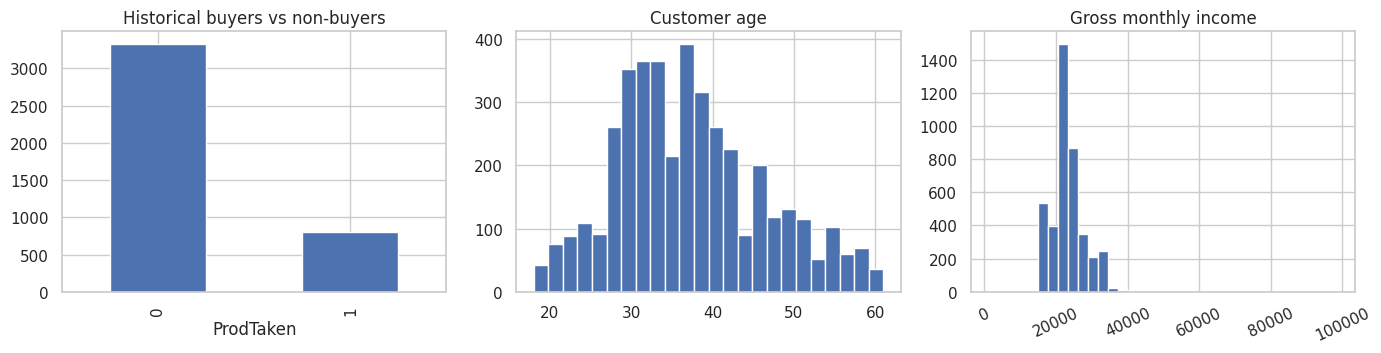

In [4]:
fig,axes=plt.subplots(1,3,figsize=(14,3.7))
raw["ProdTaken"].value_counts().sort_index().plot.bar(ax=axes[0]);axes[0].set_title("Historical buyers vs non-buyers")
axes[1].hist(raw["Age"],bins=24);axes[1].set_title("Customer age")
axes[2].hist(raw["MonthlyIncome"],bins=35);axes[2].set_title("Gross monthly income");axes[2].tick_params(axis='x',rotation=25)
plt.tight_layout();plt.show()


**Univariate observations.** 797 of 4,128 historical customers purchased (19.31%), so a high overall accuracy can be achieved by predicting the majority class alone; accuracy is not a suitable primary metric. Age averages approximately 37 years. Income has a long upper tail (minimum 1,000; maximum 98,678), and trip counts include isolated values of 19–22 trips/year. These extremes need validation at source, but removing records would discard rare legitimate customers and is not justified without domain evidence. Decision-tree ensembles are relatively robust to such tails. No values are missing in the supplied CSV, but imputation remains built into the model pipeline for future data.

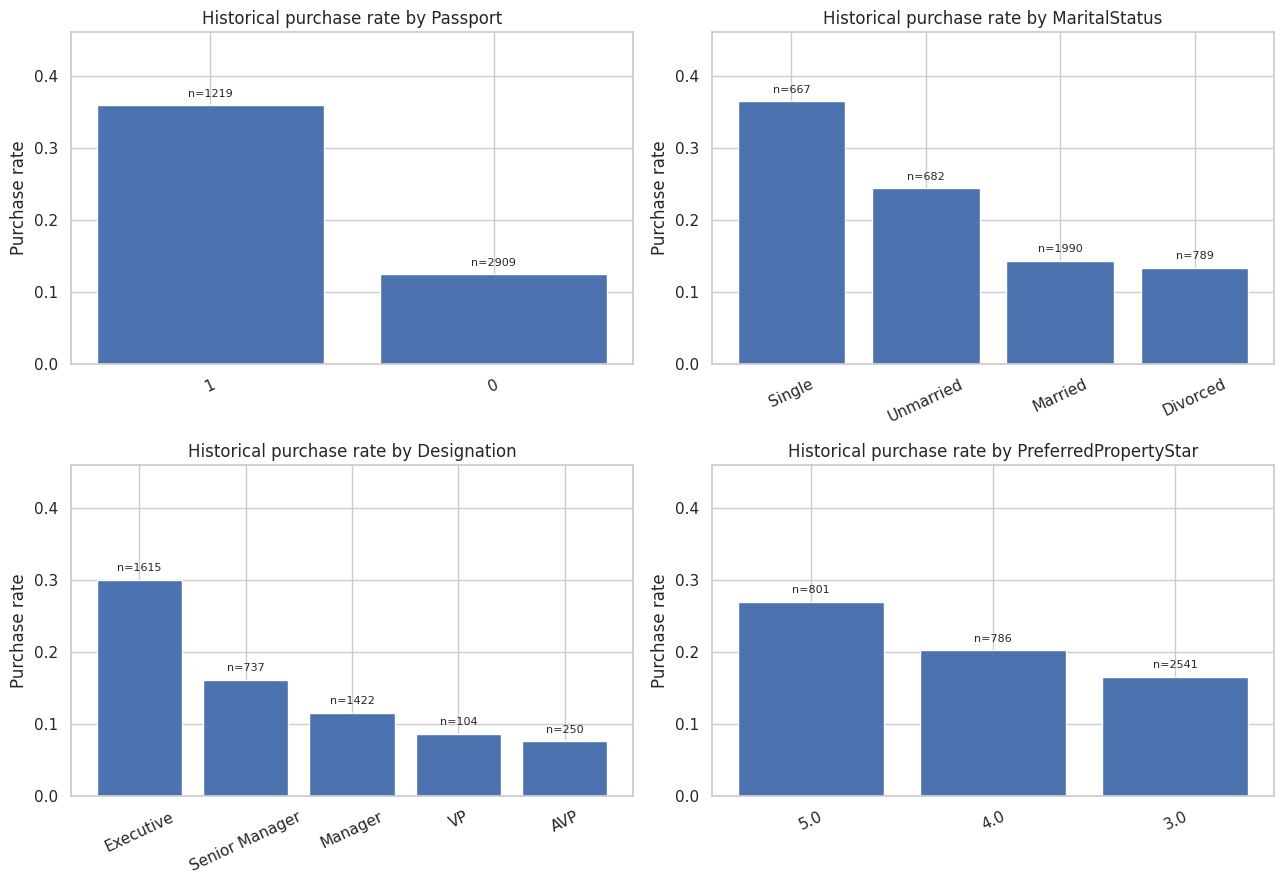


 Passport


,count,buyers,purchase_rate
Passport,,,
1,1219,437,0.358
0,2909,360,0.124



 Designation


,count,buyers,purchase_rate
Designation,,,
Executive,1615,485,0.300
Senior Manager,737,119,0.161
Manager,1422,165,0.116
VP,104,9,0.087
AVP,250,19,0.076



 MaritalStatus


,count,buyers,purchase_rate
MaritalStatus,,,
Single,667,243,0.364
Unmarried,682,166,0.243
Married,1990,283,0.142
Divorced,789,105,0.133



 PreferredPropertyStar


,count,buyers,purchase_rate
PreferredPropertyStar,,,
5.000,801,216,0.270
4.000,786,159,0.202
3.000,2541,422,0.166



 CityTier


,count,buyers,purchase_rate
CityTier,,,
2,162,43,0.265
3,1288,311,0.241
1,2678,443,0.165


In [5]:
def rates(column):
    result=raw.groupby(column,dropna=False)["ProdTaken"].agg(count="size",buyers="sum",purchase_rate="mean")
    return result.sort_values("purchase_rate",ascending=False)
fig,axs=plt.subplots(2,2,figsize=(13,9))
for ax,field in zip(axs.flat,["Passport","MaritalStatus","Designation","PreferredPropertyStar"]):
    df=rates(field).reset_index()
    ax.bar(range(len(df)), df["purchase_rate"].to_numpy());ax.set_xticks(range(len(df)),df[field].astype(str))
    ax.set_title(f"Historical purchase rate by {field}")
    ax.set_ylabel("Purchase rate")
    ax.set_ylim(0,0.46)
    ax.tick_params(axis="x",rotation=25)
    for j,row in df.iterrows():
        ax.text(j,row.purchase_rate+0.012,f"n={int(row['count'])}",ha='center',fontsize=8)
plt.tight_layout();plt.show()
for field in ["Passport","Designation","MaritalStatus","PreferredPropertyStar","CityTier"]:
    print("\n",field)
    display(rates(field).round(3))


**Bivariate observations.** Passport holders have a 35.8% historical purchase rate versus 12.4% without passports; customers labelled Executive have a 30.0% observed rate, and the group labelled Single has a 36.4% rate. Five-star property preference corresponds to a 27.0% rate versus 16.6% for three-star. These descriptive associations can support hypotheses for campaign testing; they do **not** prove causal effects, and group sizes and operational eligibility must be considered.

**Quality/lineage warning:** `ProductPitched` and `Designation` map one-to-one in the dataset (e.g. Basic ↔ Executive). This indicates strong redundant historical business-process encoding. `ProductPitched` is excluded from pre-contact modeling. `Single` and `Unmarried` are retained as distinct supplied categories pending a source-system definition; merging them silently would change the data's meaning.

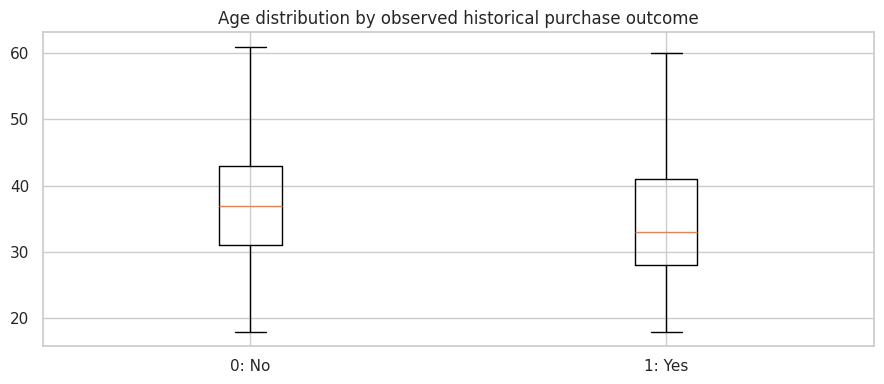

In [6]:
# Additional pairwise inspection without post-contact variables in the deployed feature set.
fig, ax=plt.subplots(figsize=(9,4))
ax.boxplot([raw.loc[raw.ProdTaken==k,"Age"].to_numpy() for k in [0,1]],tick_labels=["0: No","1: Yes"])
ax.set_title("Age distribution by observed historical purchase outcome")
plt.tight_layout();plt.show()


## 4. Data registration (3 points)

Data registration is deterministic and checks the complete data-dictionary schema (with optional extra index column), `CustomerID` uniqueness, target integrity and completeness. JSON evidence is saved for the CI job artifact. The raw CSV remains tracked under `tourism_project/data/`.

In [7]:
%%writefile tourism_project/model_building/config.py
"""Shared, leakage-safe schema for prospective customer scoring."""
from pathlib import Path

PROJECT_ROOT = Path(__file__).resolve().parents[1]
REPO_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / "data" / "tourism.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
MODEL_PATH = PROJECT_ROOT / "deployment" / "best_model.joblib"
METADATA_PATH = PROJECT_ROOT / "deployment" / "model_metadata.json"
TARGET = "ProdTaken"
ID_COLUMNS = ["CustomerID", "Unnamed: 0"]
# These fields are generated during/after the sales interaction, not at initial lead scoring.
POST_CONTACT_COLUMNS = ["TypeofContact", "DurationOfPitch", "NumberOfFollowups",
                        "ProductPitched", "PitchSatisfactionScore"]
CATEGORICAL_COLUMNS = ["Occupation", "Gender", "MaritalStatus", "Designation", "CityTier"]
NUMERIC_COLUMNS = ["Age", "NumberOfPersonVisiting", "PreferredPropertyStar",
                   "NumberOfTrips", "Passport", "OwnCar", "NumberOfChildrenVisiting",
                   "MonthlyIncome"]
FEATURE_COLUMNS = NUMERIC_COLUMNS + CATEGORICAL_COLUMNS
REQUIRED_COLUMNS = ["CustomerID", TARGET] + FEATURE_COLUMNS + POST_CONTACT_COLUMNS
SEED = 42


Overwriting tourism_project/model_building/config.py


In [8]:
%%writefile tourism_project/model_building/data_register.py
"""Register the repository-held raw CSV with schema, uniqueness and target checks."""
from __future__ import annotations
import argparse
import json
import pandas as pd
from .config import DATA_PATH, OUTPUT_DIR, REQUIRED_COLUMNS, TARGET


def validate_dataset(csv_path=DATA_PATH, report_path=None):
    source = pd.read_csv(csv_path)
    missing_columns = sorted(set(REQUIRED_COLUMNS) - set(source.columns))
    if missing_columns:
        raise ValueError(f"Required columns missing from dataset: {missing_columns}")
    if source.empty:
        raise ValueError("Dataset is empty")
    if source["CustomerID"].isna().any() or source["CustomerID"].duplicated().any():
        raise ValueError("CustomerID must be non-null and unique")
    if source[TARGET].isna().any() or not set(source[TARGET].unique()).issubset({0, 1}):
        raise ValueError("ProdTaken must contain only non-null binary values 0 and 1")
    if source[TARGET].nunique() != 2:
        raise ValueError("Both outcome classes are required for model evaluation")
    report = {
        "dataset": str(csv_path), "rows": len(source), "columns": len(source.columns),
        "unique_customers": int(source.CustomerID.nunique()),
        "duplicate_rows": int(source.duplicated().sum()),
        "missing_cells": int(source.isna().sum().sum()),
        "missing_by_column": {k:int(v) for k,v in source.isna().sum().items() if v},
        "outcomes": {str(k):int(v) for k,v in source[TARGET].value_counts().sort_index().items()},
        "historical_purchase_rate": round(float(source[TARGET].mean()), 6)
    }
    report_path = OUTPUT_DIR / "registration_report.json" if report_path is None else report_path
    report_path.parent.mkdir(parents=True, exist_ok=True)
    report_path.write_text(json.dumps(report, indent=2), encoding="utf-8")
    print(json.dumps(report, indent=2))
    return report

if __name__ == "__main__":
    parser = argparse.ArgumentParser(description="Validate tourism.csv against expected data dictionary")
    parser.add_argument("--csv", type=str, default=str(DATA_PATH))
    args = parser.parse_args()
    validate_dataset(args.csv)


Overwriting tourism_project/model_building/data_register.py


In [9]:
from tourism_project.model_building.data_register import validate_dataset
register_summary = validate_dataset()
assert register_summary["rows"] == len(raw)


{
  "dataset": "/mnt/data/Visit_With_Us_MLOps/tourism_project/data/tourism.csv",
  "rows": 4128,
  "columns": 21,
  "unique_customers": 4128,
  "duplicate_rows": 0,
  "missing_cells": 0,
  "missing_by_column": {},
  "outcomes": {
    "0": 3331,
    "1": 797
  },
  "historical_purchase_rate": 0.193072
}


## 5. Data preparation, leakage control and train/test artifact (7 points)

`CustomerID` and `Unnamed: 0` are identifiers, not behavioral features. `TypeofContact`, `ProductPitched`, `DurationOfPitch`, `NumberOfFollowups`, and `PitchSatisfactionScore` are associated with sales assignment or interactions and are excluded from **before-contact** scoring. The `Fe Male` typo is normalized to `Female` (155 rows). Other categorical labels are preserved as supplied. No rows are discarded for numeric extremes without validation; all imputation and one-hot encoding occur inside training folds. We use a reproducible 80/20 stratified split.

In [10]:
%%writefile tourism_project/model_building/prep.py
"""Deterministic preprocessing and stratified holdout; no holdout-driven imputation."""
from __future__ import annotations
import json
import pandas as pd
from sklearn.model_selection import train_test_split
from .config import (DATA_PATH, OUTPUT_DIR, TARGET, FEATURE_COLUMNS,
                     CATEGORICAL_COLUMNS, NUMERIC_COLUMNS, SEED)
from .data_register import validate_dataset


def clean_data(df):
    """Apply canonical labels and remove identifiers and post-contact features.

    Numeric missingness is retained here and imputed using *training folds only*
    within the modeling pipeline, avoiding information leakage.
    """
    df = df.copy()
    df["Gender"] = (df["Gender"].astype("string").str.strip()
                    .replace({"Fe Male": "Female"}))
    for column in (set(CATEGORICAL_COLUMNS) - {"CityTier"}):
        df[column] = df[column].astype("string").str.strip().replace({"": pd.NA})
        # Object strings are supported reliably by OneHotEncoder across environments.
        df[column] = df[column].astype(object).where(df[column].notna(), None)
    for column in NUMERIC_COLUMNS + ["CityTier"]:
        df[column] = pd.to_numeric(df[column], errors="coerce")
    df[TARGET] = pd.to_numeric(df[TARGET], errors="raise").astype(int)
    return df[FEATURE_COLUMNS + [TARGET]]


def prepare_data(csv_path=DATA_PATH, output_dir=OUTPUT_DIR, test_size=0.20):
    validate_dataset(csv_path)
    raw = pd.read_csv(csv_path)
    cleaned = clean_data(raw)
    X = cleaned[FEATURE_COLUMNS]
    y = cleaned[TARGET]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=SEED, stratify=y
    )
    output_dir.mkdir(parents=True, exist_ok=True)
    for filename, df in [("Xtrain.csv", X_train), ("Xtest.csv", X_test),
                         ("ytrain.csv", y_train.to_frame()), ("ytest.csv", y_test.to_frame())]:
        df.reset_index(drop=True).to_csv(output_dir / filename, index=False)
    report = {
        "training_rows": len(X_train), "holdout_rows": len(X_test),
        "training_purchase_rate": round(float(y_train.mean()), 6),
        "holdout_purchase_rate": round(float(y_test.mean()), 6),
        "available_at_scoring": FEATURE_COLUMNS,
        "excluded_post_contact_fields": ["TypeofContact", "DurationOfPitch",
                                         "NumberOfFollowups", "ProductPitched", "PitchSatisfactionScore"],
        "gender_typo_normalized": int(raw["Gender"].eq("Fe Male").sum())
    }
    (output_dir / "preparation_report.json").write_text(json.dumps(report, indent=2), encoding="utf-8")
    print(json.dumps(report, indent=2))
    return X_train, X_test, y_train, y_test

if __name__ == "__main__":
    prepare_data()


Overwriting tourism_project/model_building/prep.py


In [11]:
from tourism_project.model_building.prep import prepare_data, clean_data
from tourism_project.model_building.config import FEATURE_COLUMNS, OUTPUT_DIR, MODEL_PATH, METADATA_PATH
X_train, X_test, y_train, y_test = prepare_data()
print("Training samples:",len(X_train),"; Holdout samples:",len(X_test))
print("Leakage-safe predictors:",len(FEATURE_COLUMNS))
display(pd.DataFrame({"partition":["train","holdout"],"rows":[len(y_train),len(y_test)],
                      "purchase_rate":[y_train.mean(),y_test.mean()]}))


{
  "dataset": "/mnt/data/Visit_With_Us_MLOps/tourism_project/data/tourism.csv",
  "rows": 4128,
  "columns": 21,
  "unique_customers": 4128,
  "duplicate_rows": 0,
  "missing_cells": 0,
  "missing_by_column": {},
  "outcomes": {
    "0": 3331,
    "1": 797
  },
  "historical_purchase_rate": 0.193072
}


{
  "training_rows": 3302,
  "holdout_rows": 826,
  "training_purchase_rate": 0.193216,
  "holdout_purchase_rate": 0.192494,
  "available_at_scoring": [
    "Age",
    "NumberOfPersonVisiting",
    "PreferredPropertyStar",
    "NumberOfTrips",
    "Passport",
    "OwnCar",
    "NumberOfChildrenVisiting",
    "MonthlyIncome",
    "Occupation",
    "Gender",
    "MaritalStatus",
    "Designation",
    "CityTier"
  ],
  "excluded_post_contact_fields": [
    "TypeofContact",
    "DurationOfPitch",
    "NumberOfFollowups",
    "ProductPitched",
    "PitchSatisfactionScore"
  ],
  "gender_typo_normalized": 155
}
Training samples: 3302 ; Holdout samples: 826
Leakage-safe predictors: 13


,partition,rows,purchase_rate
0,train,3302,0.193
1,holdout,826,0.192


**Artifact contract:** Preparation writes `Xtrain.csv`, `Xtest.csv`, `ytrain.csv`, and `ytest.csv` to `tourism_project/outputs/`. `actions/upload-artifact@v4` publishes them as `prepared-splits`, which the model-training job downloads before fitting. Keeping preprocessing within the model pipeline prevents holdout-derived medians or category distributions from leaking into cross-validation.

## 6. Model building, experiment tracking and model selection (13 points)

Two eligible ensemble families are tuned: **RandomForestClassifier** (8 parameter combinations) and **GradientBoostingClassifier** (4 combinations), using three-fold stratified training CV. Each of the 12 trials records the tuned parameters and CV mean/standard deviation. MLflow tracks trials when installed and stores the champion with artifacts. This local runtime cannot install MLflow, so a transparent experiment JSON ledger is used here; the GitHub workflow installs MLflow and executes the exact same training script with tracking enabled.

In [12]:
%%writefile tourism_project/model_building/train.py
"""Fit models, tune average precision, log experiments and export the winner.

MLflow uses a local file store in Actions, archived as a workflow artifact. For an
offline notebook runtime without MLflow, a complete JSON experiment ledger is
still written; CI installs MLflow and performs full tracking.
"""
from __future__ import annotations
import json
from datetime import datetime, timezone
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             precision_score, recall_score, f1_score,
                             balanced_accuracy_score, confusion_matrix, brier_score_loss)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from .config import (OUTPUT_DIR, MODEL_PATH, METADATA_PATH, TARGET, SEED,
                     FEATURE_COLUMNS, CATEGORICAL_COLUMNS, NUMERIC_COLUMNS)


def top_fraction_metrics(y_true, probabilities, fraction=0.20):
    """Assess how effectively a fixed-size contact list captures past buyers."""
    y_true = np.asarray(y_true, dtype=int)
    probabilities = np.asarray(probabilities, dtype=float)
    size = max(1, int(np.ceil(len(y_true) * fraction)))
    chosen = np.argsort(-probabilities, kind="stable")[:size]
    selected_positive = int(y_true[chosen].sum())
    precision = selected_positive / size
    baseline = float(y_true.mean())
    return {
        "top20_precision": float(precision),
        "top20_recall": float(selected_positive / max(1, int(y_true.sum()))),
        "top20_lift": float(precision / baseline) if baseline > 0 else 0.0,
        "top20_contact_count": int(size), "top20_actual_buyers": selected_positive
    }


def build_pipeline(estimator):
    transformer = ColumnTransformer(
        transformers=[
            ("num", SimpleImputer(strategy="median"), NUMERIC_COLUMNS),
            ("cat", Pipeline(steps=[
                ("impute", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
            ]), CATEGORICAL_COLUMNS)
        ], remainder="drop", verbose_feature_names_out=False
    )
    return Pipeline(steps=[("preprocessor", transformer), ("classifier", estimator)])


def candidate_grids():
    return {
        "RandomForest": (
            RandomForestClassifier(random_state=SEED, class_weight="balanced_subsample", n_jobs=1),
            {"classifier__n_estimators": [150, 250],
             "classifier__max_depth": [8, None],
             "classifier__min_samples_leaf": [2, 5]}
        ),
        "GradientBoosting": (
            GradientBoostingClassifier(random_state=SEED),
            {"classifier__n_estimators": [100, 180],
             "classifier__learning_rate": [0.05, 0.10],
             "classifier__max_depth": [2]}
        )
    }


def train_model(split_dir=OUTPUT_DIR, model_path=MODEL_PATH, metadata_path=METADATA_PATH):
    X_train = pd.read_csv(split_dir / "Xtrain.csv")
    X_test = pd.read_csv(split_dir / "Xtest.csv")
    y_train = pd.read_csv(split_dir / "ytrain.csv")[TARGET].astype(int)
    y_test = pd.read_csv(split_dir / "ytest.csv")[TARGET].astype(int)
    # Data contracts: prohibit accidentally training with retrospective inputs.
    if X_train.columns.tolist() != FEATURE_COLUMNS or X_test.columns.tolist() != FEATURE_COLUMNS:
        raise ValueError("Feature order or pre-contact schema does not match config.py")
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
    leaderboard = []
    all_trials = []
    winners = {}

    # Soft availability check is solely for offline execution without network.
    try:
        import mlflow
        mlflow.set_tracking_uri((split_dir / "mlruns").resolve().as_uri())
        mlflow.set_experiment("Tourism-PreContact-Propensity")
        tracking_enabled = True
    except ImportError:
        mlflow = None
        tracking_enabled = False
        print("Local MLflow unavailable; full trial log saved to JSON. GitHub Actions installs MLflow.")

    for name, (estimator, grid_params) in candidate_grids().items():
        search = GridSearchCV(
            build_pipeline(estimator), grid_params, cv=cv, scoring="average_precision",
            n_jobs=1, refit=True, verbose=0, return_train_score=False
        )
        search.fit(X_train, y_train)
        trials = []
        for index, params in enumerate(search.cv_results_["params"]):
            trial = {
                "model": name, "trial": index + 1,
                "params": {key: (None if val is None else val) for key, val in params.items()},
                "mean_cv_average_precision": float(search.cv_results_["mean_test_score"][index]),
                "std_cv_average_precision": float(search.cv_results_["std_test_score"][index])
            }
            trials.append(trial)
            all_trials.append(trial)
            if tracking_enabled:
                with mlflow.start_run(run_name=f"{name}-trial-{index + 1}"):
                    mlflow.log_params({k: "None" if v is None else v for k, v in params.items()})
                    mlflow.log_metric("cv_average_precision", trial["mean_cv_average_precision"])
                    mlflow.log_metric("cv_average_precision_std", trial["std_cv_average_precision"])
        leaderboard.append({"model": name,
                            "cv_average_precision": float(search.best_score_),
                            "best_params": search.best_params_,
                            "trials": len(trials)})
        winners[name] = search.best_estimator_
        print(f"{name}: best CV average precision={search.best_score_:.4f}; "
              f"best params={search.best_params_}")

    # Holdout is deliberately NOT used to select model family or hyperparameters.
    chosen = max(leaderboard, key=lambda row: row["cv_average_precision"])
    final_model = winners[chosen["model"]]
    prob = final_model.predict_proba(X_test)[:, 1]
    label = (prob >= 0.50).astype(int)
    metrics = {
        "average_precision": float(average_precision_score(y_test, prob)),
        "roc_auc": float(roc_auc_score(y_test, prob)),
        "precision_at_0_5": float(precision_score(y_test, label, zero_division=0)),
        "recall_at_0_5": float(recall_score(y_test, label, zero_division=0)),
        "f1_at_0_5": float(f1_score(y_test, label, zero_division=0)),
        "balanced_accuracy_at_0_5": float(balanced_accuracy_score(y_test, label)),
        "brier_score": float(brier_score_loss(y_test, prob)),
        **top_fraction_metrics(y_test, prob)
    }
    # Data summary is for audit and does not imply wellness-specific target validation.
    metadata = {
        "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "trained_on": "historical generic travel-package purchase outcomes",
        "not_yet_validated_on": "new Wellness Tourism Package",
        "scoring_point": "before sales contact",
        "model_family": chosen["model"],
        "selection_criterion": "3-fold stratified CV average precision on training data",
        "cv_average_precision": chosen["cv_average_precision"],
        "best_params": chosen["best_params"],
        "feature_names": FEATURE_COLUMNS,
        "decision_threshold": 0.5,
        "test_rows": int(len(y_test)),
        "holdout_positive_rate": float(y_test.mean()),
        "test_metrics": metrics,
        "confusion_matrix_0_5": confusion_matrix(y_test, label).tolist(),
        "mlflow_tracking_enabled": tracking_enabled,
        "candidate_models": leaderboard
    }
    model_path.parent.mkdir(parents=True, exist_ok=True)
    joblib.dump(final_model, model_path, compress=3)
    metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")
    (split_dir / "experiment_trials.json").write_text(json.dumps(all_trials, indent=2), encoding="utf-8")
    (split_dir / "holdout_predictions.csv").write_text(
        pd.DataFrame({"actual": y_test, "pred_probability": prob,
                      "predicted_at_0_5": label}).to_csv(index=False), encoding="utf-8")
    if tracking_enabled:
        with mlflow.start_run(run_name=f"CHAMPION-{chosen['model']}"):
            mlflow.log_param("model_family", chosen["model"])
            mlflow.log_params({k: "None" if v is None else v for k,v in chosen["best_params"].items()})
            mlflow.log_metrics({k:v for k,v in metrics.items() if isinstance(v, (float,int))})
            mlflow.log_metric("best_cv_average_precision", chosen["cv_average_precision"])
            mlflow.log_artifact(str(model_path), artifact_path="model")
            mlflow.log_artifact(str(metadata_path), artifact_path="evaluation")
            mlflow.log_artifact(str(split_dir / "experiment_trials.json"), artifact_path="evaluation")
    print(json.dumps({"selected_model": chosen["model"], "cv_ap": chosen["cv_average_precision"],
                      "holdout_metrics": metrics}, indent=2))
    return final_model, metadata

if __name__ == "__main__":
    train_model()


Overwriting tourism_project/model_building/train.py


In [13]:
from tourism_project.model_building.train import train_model
from tourism_project.model_building.config import OUTPUT_DIR
best_model, model_card = train_model()
print("Serialized trained model exists:",MODEL_PATH.exists())
print("Model card exists:",METADATA_PATH.exists())


Local MLflow unavailable; full trial log saved to JSON. GitHub Actions installs MLflow.


RandomForest: best CV average precision=0.7043; best params={'classifier__max_depth': None, 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 150}


GradientBoosting: best CV average precision=0.6061; best params={'classifier__learning_rate': 0.1, 'classifier__max_depth': 2, 'classifier__n_estimators': 180}


{
  "selected_model": "RandomForest",
  "cv_ap": 0.7043494647703085,
  "holdout_metrics": {
    "average_precision": 0.7254959782932485,
    "roc_auc": 0.9150990542464618,
    "precision_at_0_5": 0.7338709677419355,
    "recall_at_0_5": 0.5723270440251572,
    "f1_at_0_5": 0.6431095406360424,
    "balanced_accuracy_at_0_5": 0.7614258908281708,
    "brier_score": 0.09400373743321178,
    "top20_precision": 0.6325301204819277,
    "top20_recall": 0.660377358490566,
    "top20_lift": 3.285974085019322,
    "top20_contact_count": 166,
    "top20_actual_buyers": 105
  }
}
Serialized trained model exists: True
Model card exists: True


Total evaluated hyperparameter combinations: 12


,model,trial,params,mean_cv_average_precision,std_cv_average_precision
4,RandomForest,5,"{'classifier__max_depth': None, 'classifier__m...",0.704,0.019
5,RandomForest,6,"{'classifier__max_depth': None, 'classifier__m...",0.703,0.018
7,RandomForest,8,"{'classifier__max_depth': None, 'classifier__m...",0.648,0.020
6,RandomForest,7,"{'classifier__max_depth': None, 'classifier__m...",0.646,0.020
0,RandomForest,1,"{'classifier__max_depth': 8, 'classifier__min_...",0.639,0.027
1,RandomForest,2,"{'classifier__max_depth': 8, 'classifier__min_...",0.638,0.026
3,RandomForest,4,"{'classifier__max_depth': 8, 'classifier__min_...",0.622,0.024
2,RandomForest,3,"{'classifier__max_depth': 8, 'classifier__min_...",0.621,0.024


,model,cv_average_precision,trials
0,RandomForest,0.704,8
1,GradientBoosting,0.606,4


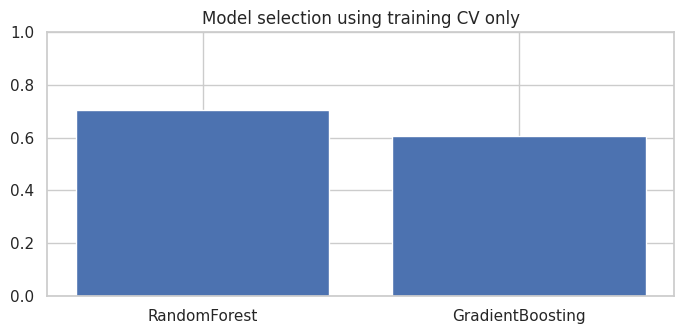

In [14]:
trials = pd.read_json(OUTPUT_DIR / "experiment_trials.json")
trial_view=trials[["model","trial","mean_cv_average_precision","std_cv_average_precision"]].copy()
print("Total evaluated hyperparameter combinations:",len(trial_view))
display(trials.sort_values('mean_cv_average_precision',ascending=False).head(8))
cv_cmp=pd.DataFrame(model_card["candidate_models"])[["model","cv_average_precision","trials"]]
display(cv_cmp)
fig,ax=plt.subplots(figsize=(7,3.5))
ax.bar(cv_cmp['model'],cv_cmp['cv_average_precision'])
ax.set_ylim(0,1);ax.set_title('Model selection using training CV only')
plt.tight_layout();plt.show()


**Experimentation decision.** The winner is selected on mean cross-validated average precision, never by peeking at holdout performance. The final serialized `Pipeline` contains its own imputation and one-hot encoding, which ensures consistent Streamlit inference. MLflow trials are retained as a GitHub Actions downloadable artifact; local offline JSON is an audit fallback, not a substitute claim for remotely executed MLflow.

## 7. Held-out evaluation, ranked targeting and model interpretation

In [15]:
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay,
                             RocCurveDisplay, classification_report)
import joblib
m=model_card["test_metrics"]
summary=pd.Series(m,name="Holdout value").to_frame()
display(summary)
print("Confusion matrix TN/FP/FN/TP:",model_card["confusion_matrix_0_5"])
print("Holdout vs baseline AP:",round(m["average_precision"],3),"vs",round(model_card["holdout_positive_rate"],3))
print("Observed lift at 20% contact capacity:",round(m["top20_lift"],2),"x")
pred=pd.read_csv(OUTPUT_DIR / "holdout_predictions.csv")
print(classification_report(pred.actual,pred.predicted_at_0_5,zero_division=0,digits=3))


,Holdout value
average_precision,0.725
roc_auc,0.915
precision_at_0_5,0.734
recall_at_0_5,0.572
f1_at_0_5,0.643
balanced_accuracy_at_0_5,0.761
brier_score,0.094
top20_precision,0.633
top20_recall,0.660
top20_lift,3.286


Confusion matrix TN/FP/FN/TP: [[634, 33], [68, 91]]
Holdout vs baseline AP: 0.725 vs 0.192
Observed lift at 20% contact capacity: 3.29 x
              precision    recall  f1-score   support

           0      0.903     0.951     0.926       667
           1      0.734     0.572     0.643       159

    accuracy                          0.878       826
   macro avg      0.819     0.761     0.785       826
weighted avg      0.871     0.878     0.872       826



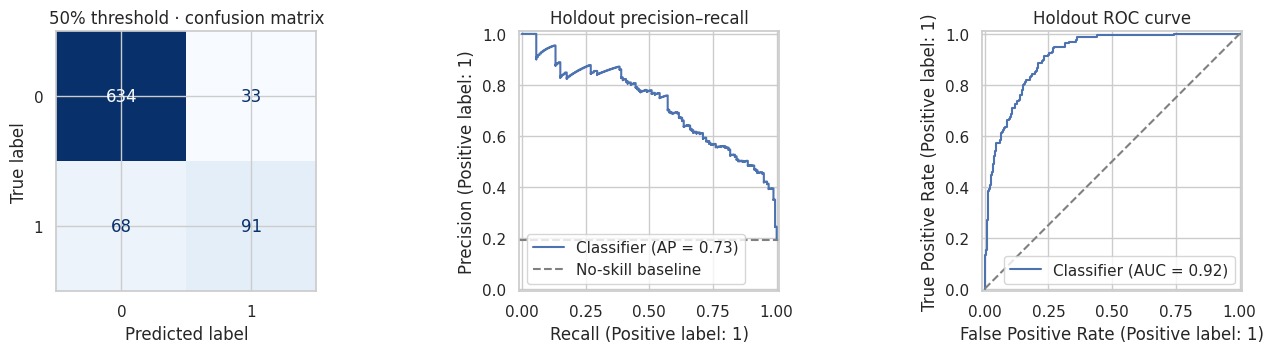

In [16]:
fig,axs=plt.subplots(1,3,figsize=(14,3.7))
ConfusionMatrixDisplay.from_predictions(pred.actual,pred.predicted_at_0_5,ax=axs[0],cmap="Blues",colorbar=False)
axs[0].set_title('50% threshold · confusion matrix')
PrecisionRecallDisplay.from_predictions(pred.actual,pred.pred_probability,ax=axs[1])
axs[1].axhline(model_card["holdout_positive_rate"],linestyle='--',color='gray',label='No-skill baseline')
axs[1].legend(loc='lower left');axs[1].set_title('Holdout precision–recall')
RocCurveDisplay.from_predictions(pred.actual,pred.pred_probability,ax=axs[2])
axs[2].plot([0,1],[0,1],'--',color='gray');axs[2].set_title('Holdout ROC curve')
plt.tight_layout();plt.show()


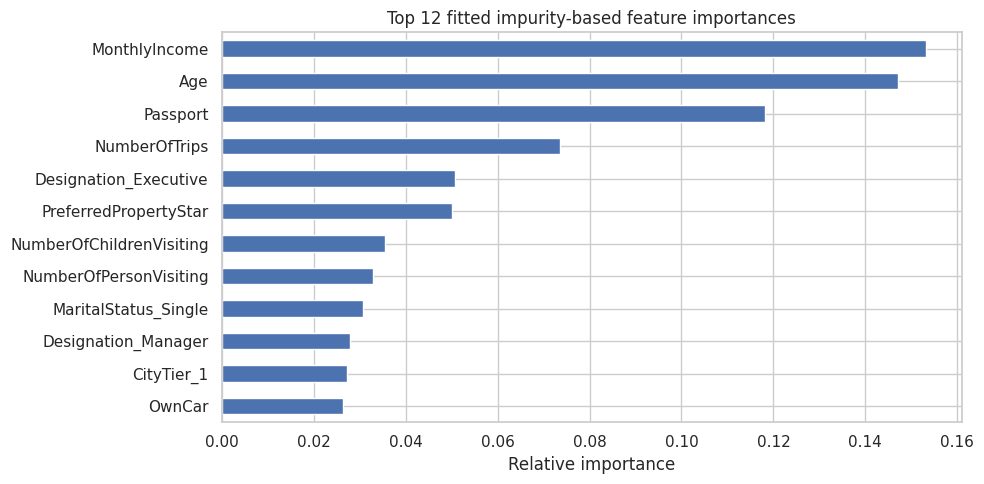

Top 12 model signals (associational, not causal):


,importance
MonthlyIncome,0.153
Age,0.147
Passport,0.118
NumberOfTrips,0.074
Designation_Executive,0.051
PreferredPropertyStar,0.050
NumberOfChildrenVisiting,0.036
NumberOfPersonVisiting,0.033
MaritalStatus_Single,0.031
Designation_Manager,0.028


In [17]:
# Expose explainable but NON-causal fitted feature importances from the winning tree ensemble.
processor=best_model.named_steps['preprocessor']
classifier=best_model.named_steps['classifier']
expanded=processor.get_feature_names_out()
importances=pd.Series(classifier.feature_importances_,index=expanded).sort_values(ascending=False)
fig,ax=plt.subplots(figsize=(10,5))
importances.head(12).sort_values().plot(kind='barh',ax=ax)
ax.set_title('Top 12 fitted impurity-based feature importances')
ax.set_xlabel('Relative importance');plt.tight_layout();plt.show()
print('Top 12 model signals (associational, not causal):')
display(importances.head(12).rename('importance').to_frame())


In [18]:
# Explicit scoring proof: the same object saved to disk produces the same probabilities.
loaded_model=joblib.load(MODEL_PATH)
example=X_test.head(3)
scored=pd.DataFrame({"score":loaded_model.predict_proba(example)[:,1],
                     "historical_label":y_test.head(3).values})
display(scored)
np.testing.assert_allclose(best_model.predict_proba(example), loaded_model.predict_proba(example))
print('Serialization and input-column contract verified.')


,score,historical_label
0,0.050,0
1,0.099,0
2,0.334,0


Serialization and input-column contract verified.


**Holdout interpretation.** The selected Random Forest achieves CV average precision around **0.704**, held-out average precision **0.725**, ROC-AUC **0.915**, precision **0.734** and recall **0.572** at a 0.50 threshold. The top-ranked 20% of holdout records (166 contacts) contain **105** historical buyers (63.3% precision, **3.29×** lift versus a random 20% contact allocation). This captures **66.0%** of the 159 holdout buyers while prioritising only 20.1% of prospects. The strong ranking performance is promising but may partly reflect dataset-specific business relationships and may not transfer to new wellness products. A threshold of 0.50 is illustrative, not optimized for contact costs or probability calibration.

**Caution on feature importance:** Impurity-based importances may overstate high-cardinality continuous fields and are non-causal; use permutation importance, stability checks and campaign experiments to confirm practical relevance before automating spend.

## 8. Model deployment: Streamlit app and dependencies (11 points)

The app reads the **same committed model and model card** as the training pipeline, collects **all 13 available-at-scoring inputs** into a DataFrame in the **exact trained column order**, and displays an explanatory propensity score. The app does not require an ngrok tunnel or Colab, and contains prominent warnings about the new wellness-package label limitation. 

In [19]:
%%writefile tourism_project/deployment/app.py
"""Streamlit Community Cloud app: prospective historical-purchase propensity."""
from __future__ import annotations
import json
from pathlib import Path
import joblib
import pandas as pd
import streamlit as st

DEPLOY_DIR = Path(__file__).resolve().parent
MODEL_FILE = DEPLOY_DIR / "best_model.joblib"
METADATA_FILE = DEPLOY_DIR / "model_metadata.json"
st.set_page_config(page_title="Visit with Us | Lead Prioritisation", page_icon="🌿", layout="wide")

@st.cache_resource
def get_model():
    return joblib.load(MODEL_FILE)

st.title("🌿 Visit with Us · Lead Prioritisation")
st.write("Predict **historical travel-package purchase propensity** using information available *before* sales contact.")
st.info("Research prototype: historical package outcomes are not verified Wellness Tourism Package outcomes. Validate on wellness-specific labelled customers before commercial rollout.")
if not MODEL_FILE.exists() or not METADATA_FILE.exists():
    st.error("Trained model not found. Run the GitHub Actions pipeline and commit best_model.joblib before deployment.")
    st.stop()
model = get_model()
metadata = json.loads(METADATA_FILE.read_text(encoding="utf-8"))

with st.form("customer"):
    st.subheader("Prospective customer profile")
    c1,c2,c3 = st.columns(3)
    with c1:
        age=st.number_input("Age", min_value=18, max_value=100, value=37)
        city=st.selectbox("City tier", [1,2,3])
        occupation=st.selectbox("Occupation", ["Salaried","Small Business","Large Business","Free Lancer"])
        gender=st.selectbox("Gender", ["Female","Male"])
        marital=st.selectbox("Marital status", ["Married","Single","Unmarried","Divorced"])
    with c2:
        people=st.number_input("People visiting", min_value=1,max_value=20,value=3)
        stars=st.selectbox("Preferred hotel stars", [3,4,5])
        trips=st.number_input("Trips per year", min_value=0,max_value=30,value=3)
        passport=st.selectbox("Valid passport", [0,1], format_func=lambda x:"Yes" if x else "No")
        car=st.selectbox("Owns a car", [0,1], format_func=lambda x:"Yes" if x else "No")
    with c3:
        children=st.number_input("Children under 5 visiting",min_value=0,max_value=10,value=1)
        designation=st.selectbox("Job designation", ["Executive","Manager","Senior Manager","AVP","VP"])
        income=st.number_input("Gross monthly income (dataset units)",min_value=0,max_value=300000,value=23000,step=500)
        st.caption("Use the same income units as the training dataset; its currency was not specified.")
    submitted=st.form_submit_button("Score customer", type="primary", use_container_width=True)

if submitted:
    row = {
        "Age":float(age), "NumberOfPersonVisiting":int(people),
        "PreferredPropertyStar":int(stars), "NumberOfTrips":int(trips),
        "Passport":int(passport), "OwnCar":int(car),
        "NumberOfChildrenVisiting":int(children), "MonthlyIncome":float(income),
        "Occupation":occupation, "Gender":gender, "MaritalStatus":marital,
        "Designation":designation,"CityTier":int(city)
    }
    df = pd.DataFrame([row], columns=metadata["feature_names"])
    score = float(model.predict_proba(df)[0,1])
    st.metric("Estimated historical-purchase propensity", f"{score:.1%}")
    st.progress(min(1.0, max(0.0, score)))
    if score >= metadata["decision_threshold"]:
        st.success("Above the illustrative 50% score threshold. Consider for priority review.")
    else:
        st.write("Below the illustrative 50% threshold. Consider ranking with the wider lead pool before allocating contact capacity.")
    st.caption("A prediction is not a guaranteed purchase. Scores are not proven calibrated; benchmark campaign lift prospectively.")

with st.expander("Model card and governance", expanded=False):
    st.write("**Model:**",metadata["model_family"])
    st.write("**Training choice:**",metadata["selection_criterion"])
    st.write("**Holdout average precision:**",f"{metadata['test_metrics']['average_precision']:.3f}")
    st.write("**Holdout top-20% lift:**",f"{metadata['test_metrics']['top20_lift']:.2f}×")
    st.write("**Inputs:** 13 pre-contact fields; no pitch or follow-up variables")
    st.write("**Limitations:** target is past product purchase; monitor data drift, disparate outcomes, and retrain only with labelled customers")


Overwriting tourism_project/deployment/app.py


In [20]:
%%writefile tourism_project/deployment/requirements.txt
# Streamlit Community Cloud; keep serialization stack consistent with training.
numpy==2.2.6
pandas==2.2.3
scikit-learn==1.8.0
joblib==1.5.3
streamlit==1.48.1


Overwriting tourism_project/deployment/requirements.txt


In [21]:
%%writefile tourism_project/requirements.txt
# Training / CI dependencies; Python 3.11 across GitHub Actions and Community Cloud
numpy==2.2.6
pandas==2.2.3
scikit-learn==1.8.0
joblib==1.5.3
mlflow==3.0.1
pytest==8.4.2


Overwriting tourism_project/requirements.txt


## 9. GitHub Actions CI/CD pipeline (15 points)

The YAML has four explicit, ordered jobs: `register-dataset` → `data-prep` → `model-training` → `publish-model`. Each job checks out the repository. Preparation *downloads* the registered dataset evidence and *uploads* the train/test artifact. Training downloads the four splits, tunes the candidates, produces JSON + MLflow experiment logs, validates predictions through tests and publishes an artifact. The final job retrieves the model and commits it to `main` using GitHub's built-in `GITHUB_TOKEN`, avoiding plaintext PATs. `[skip ci]` and `paths-ignore` prevent training loops from model-only updates. Repository branch-protection and Actions write permission must permit a bot commit.

In [22]:
%%writefile .github/workflows/pipeline.yml
name: Tourism propensity — validate, prepare, train and publish

on:
  push:
    branches: [main]
    paths-ignore:
      - "tourism_project/deployment/best_model.joblib"
      - "tourism_project/deployment/model_metadata.json"
      - "tourism_project/outputs/**"
      - "**/*.md"
  workflow_dispatch:

permissions:
  contents: write

concurrency:
  group: tourism-mlops-${{ github.ref }}
  cancel-in-progress: false

jobs:
  register-dataset:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: '3.11'
          cache: pip
          cache-dependency-path: tourism_project/requirements.txt
      - name: Install project dependencies
        run: pip install -r tourism_project/requirements.txt
      - name: Validate and register data
        run: python -m tourism_project.model_building.data_register
      - uses: actions/upload-artifact@v4
        with:
          name: registered-data
          path: |
            tourism_project/data/tourism.csv
            tourism_project/outputs/registration_report.json

  data-prep:
    needs: register-dataset
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: '3.11'
          cache: pip
          cache-dependency-path: tourism_project/requirements.txt
      - name: Install project dependencies
        run: pip install -r tourism_project/requirements.txt
      - name: Download and verify registered data
        uses: actions/download-artifact@v4
        with:
          name: registered-data
          path: tourism_project/registered-artifact
      - name: Confirm repository input agrees with artifact
        run: cmp tourism_project/data/tourism.csv tourism_project/registered-artifact/data/tourism.csv
      - name: Clean and split data
        run: python -m tourism_project.model_building.prep
      - uses: actions/upload-artifact@v4
        with:
          name: prepared-splits
          path: |
            tourism_project/outputs/Xtrain.csv
            tourism_project/outputs/Xtest.csv
            tourism_project/outputs/ytrain.csv
            tourism_project/outputs/ytest.csv
            tourism_project/outputs/preparation_report.json

  model-training:
    needs: data-prep
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: '3.11'
          cache: pip
          cache-dependency-path: tourism_project/requirements.txt
      - name: Install project dependencies
        run: pip install -r tourism_project/requirements.txt
      - name: Download training and holdout splits
        uses: actions/download-artifact@v4
        with:
          name: prepared-splits
          path: tourism_project/outputs
      - name: Tune candidates, track MLflow trials, export best model
        run: python -m tourism_project.model_building.train
      - name: Run offline scoring smoke tests
        run: python -m pytest -q tests
      - uses: actions/upload-artifact@v4
        with:
          name: model-and-evaluation
          path: |
            tourism_project/deployment/best_model.joblib
            tourism_project/deployment/model_metadata.json
            tourism_project/outputs/experiment_trials.json
            tourism_project/outputs/holdout_predictions.csv
            tourism_project/outputs/mlruns/

  publish-model:
    needs: model-training
    runs-on: ubuntu-latest
    if: github.ref == 'refs/heads/main'
    steps:
      - uses: actions/checkout@v4
        with:
          ref: main
          persist-credentials: true
      - name: Retrieve winner and its evaluation
        uses: actions/download-artifact@v4
        with:
          name: model-and-evaluation
          path: tourism_project/published-artifact
      - name: Commit binary model and model card to main
        shell: bash
        run: |
          set -euo pipefail
          cp tourism_project/published-artifact/deployment/best_model.joblib tourism_project/deployment/
          cp tourism_project/published-artifact/deployment/model_metadata.json tourism_project/deployment/
          git config user.name 'github-actions[bot]'
          git config user.email '41898282+github-actions[bot]@users.noreply.github.com'
          git add tourism_project/deployment/best_model.joblib tourism_project/deployment/model_metadata.json
          if git diff --cached --quiet; then
            echo 'No new model changes to publish'
          else
            git commit -m 'ci: publish trained model [skip ci]'
            git push origin HEAD:main
          fi


Overwriting .github/workflows/pipeline.yml


In [23]:
%%writefile tests/test_pipeline.py
"""Lightweight CI checks; train script has already produced the model in Actions."""
import json
from pathlib import Path
import joblib
import pandas as pd
from tourism_project.model_building.config import (DATA_PATH, FEATURE_COLUMNS,
    MODEL_PATH, METADATA_PATH)
from tourism_project.model_building.data_register import validate_dataset
from tourism_project.model_building.prep import clean_data
from tourism_project.model_building.train import top_fraction_metrics


def test_registration_schema():
    report=validate_dataset(DATA_PATH)
    assert report["rows"] == report["unique_customers"]
    assert 0 < report["historical_purchase_rate"] < 1


def test_pre_contact_fields_and_canonical_gender():
    cleaned=clean_data(pd.read_csv(DATA_PATH))
    assert cleaned.drop(columns=["ProdTaken"]).columns.tolist() == FEATURE_COLUMNS
    assert "Fe Male" not in set(cleaned["Gender"])
    assert "DurationOfPitch" not in cleaned


def test_exported_model_scores():
    assert MODEL_PATH.exists() and METADATA_PATH.exists()
    model=joblib.load(MODEL_PATH)
    metadata=json.loads(METADATA_PATH.read_text(encoding="utf-8"))
    X=clean_data(pd.read_csv(DATA_PATH))[FEATURE_COLUMNS].head(4)
    probabilities=model.predict_proba(X)[:,1]
    assert len(probabilities)==4
    assert all(0 <= p <=1 for p in probabilities)
    assert metadata["feature_names"]==FEATURE_COLUMNS


def test_targeting_lift_math():
    m=top_fraction_metrics([1,0,0,0,0], [0.9,0.4,0.3,0.2,0.1], 0.2)
    assert m["top20_precision"] == 1.0
    assert m["top20_lift"] == 5.0


Overwriting tests/test_pipeline.py


In [24]:
from pathlib import Path
import yaml, ast, subprocess
workflow=yaml.safe_load(Path('.github/workflows/pipeline.yml').read_text(encoding='utf-8'))
assert list(workflow['jobs'])==['register-dataset','data-prep','model-training','publish-model']
ast.parse(Path('tourism_project/deployment/app.py').read_text(encoding='utf-8'))
print('GitHub Actions workflow parsed; jobs:', ' → '.join(workflow['jobs']))
result=subprocess.run([sys.executable,'-m','pytest','-q','tests'],capture_output=True,text=True,check=True)
print(result.stdout)


GitHub Actions workflow parsed; jobs: register-dataset → data-prep → model-training → publish-model


....                                                                     [100%]
4 passed in 1.75s



### GitHub publishing — required external steps

This notebook does not print or store credentials. **Create a new GitHub repository**, for example `visit-with-us-tourism-mlops`, then from the supplied repository folder run:

```bash
git init
git checkout -b main
git add .github tourism_project tests README.md .gitignore
git commit -m "Initial reproducible tourism MLOps pipeline"
git remote add origin https://github.com/<YOUR_USERNAME>/<YOUR_NEW_REPOSITORY>.git
git push -u origin main
```

Prefer the GitHub sign-in credential manager or your existing authenticated `gh` CLI; do not insert personal access tokens in notebooks. In **Settings → Actions → General → Workflow permissions**, enable read/write access if necessary for automated model commits. Use the Actions tab for run evidence. In Streamlit Community Cloud, configure repository `main`, application path `tourism_project/deployment/app.py`, Python 3.11; its adjacent requirements file is installed automatically.

The *repository link* and *Streamlit URL* must refer to actual completed deployments; they cannot be verified or invented locally.

## 10. Output Evaluation (4 points) — evidence integrity

| Requirement | Evidence/status at export |
|---|---|
| Reproducible folder structure | Supplied repository ZIP and generated local inventory below |
| GitHub repository link | **Not yet published** — paste actual repo URL after pushing |
| GitHub Actions completed workflow screenshot | **Pending remote execution** — capture genuine successful workflow from Actions |
| Streamlit Community Cloud app URL | **Pending owner deployment** — paste actual `*.streamlit.app` link |
| Streamlit application screenshot | **Pending actual Streamlit deployment** — capture from running public app |

Do not present a locally rendered picture as proof of GitHub/Streamlit deployment. Update the last four items and re-export HTML after deployment for full Output Evaluation credit.

In [25]:
# Actual local folder inventory (not a GitHub web screenshot).
for path in sorted(Path('tourism_project').rglob('*')):
    if not path.is_file() or any(x in path.parts for x in ['__pycache__','outputs']):
        continue
    print(str(path))
print('Workflow:',Path('.github/workflows/pipeline.yml').exists())


tourism_project/__init__.py
tourism_project/data/tourism.csv
tourism_project/deployment/app.py
tourism_project/deployment/best_model.joblib
tourism_project/deployment/model_metadata.json
tourism_project/deployment/requirements.txt
tourism_project/model_building/__init__.py
tourism_project/model_building/config.py
tourism_project/model_building/data_register.py
tourism_project/model_building/prep.py
tourism_project/model_building/train.py
tourism_project/requirements.txt
Workflow: True


## 11. Business recommendations, monitoring and next steps

1. **Pilot ranked outreach with controlled measurement.** At the tested 20% budget, historical lift is about 3.29×. Randomize comparable prospects into score-ranked and business-as-usual outreach groups; track incremental conversion, contact cost and margin. Historical associations are not incremental lift.
2. **Use pre-contact predictors only.** Maintain a feature data contract and document availability timestamps. Pitch satisfaction, pitch duration and follow-up counts cannot be collected for a prospect before first contact; including them would make the app unrealistic.
3. **Collect wellness-specific labels.** Current `ProdTaken` labels describe *other historical travel purchases*. Rebuild and revalidate the pipeline on genuine Wellness Tourism Package offers and purchase outcomes before production marketing automation.
4. **Improve data governance.** Resolve the `Fe Male` typo at ingestion, clarify `Single` versus `Unmarried` in the source system, validate the four 19–22-trips observations and income extremes, and investigate the deterministic product/designation mapping to ensure no hidden process artifact is being learned.
5. **Treat scores as rankings, not guaranteed probabilities.** Recalibrate on a recent time-based holdout if probability thresholds are necessary. Track AP, top-20% precision/lift, drift, realized conversion, model/data version and observed differences across customer segments. Use separate prospective and temporal evaluation to guard against nonstationarity.
6. **Operationalize with guarded CI/CD.** Keep dataset-validation gates, split artifacts, MLflow trial records, model metadata and scoring smoke tests. Introduce staging approval and rollback before automated main-branch promotion in a production organization; retrain only when new outcome labels are available.

**Final conclusion:** The model provides a promising *historic travel-package propensity ranking* under pre-contact constraints. Successful transfer to the new wellness package and incremental campaign ROI are not yet established; production deployment must be backed by genuine wellness-package observations and a controlled pilot.

---

**Submission quality note:** The recommended submission artifact is this notebook's **executed HTML export**. The source notebook and repository ZIP are supporting implementation materials, **not additional submissions**. The original learner template's expected sections (data registration, preparation, tracked experimentation, Streamlit, CI/CD and output evidence) have been preserved and fully worked through, with unverified external steps transparently marked.